# RepViT + PP-LiteSeg for outdoor water segmentation (synthetic demo)

This notebook demonstrates a new backbone + new decoder combination added
to `swiss_army_keras`: **RepViT** (§2.4 of `plan.md`) as the encoder,
**PP-LiteSeg with UAFM** (§3.2) as the segmentation decoder, trained with
the "outdoor flooding / water" loss recipe from
[use_case_recipes.md](../../../use_case_recipes.md) §1.1:

> `0.5*Tversky(alpha=0.6) + 0.3*Lovász-Softmax + 0.2*weighted-BCE`

and the new **Lion** optimizer (§4.2).

**This notebook uses procedurally-generated synthetic data, not a real
dataset** — it exists to demonstrate that this specific
backbone+decoder+loss+optimizer combination wires together and trains
correctly end to end, not to report realistic segmentation accuracy.
Validating this recipe against a real water-segmentation dataset is tracked
separately (`plan.md` §13 Phase 8).

An earlier version of this notebook trained on only 32 examples for 15
epochs (4 steps/epoch) — far too little data for a model trained from
scratch (`weights=None`) to learn actual per-image localization, so its
predictions collapsed to a fixed, input-independent blob rather than
tracking the ellipse's real position (train loss fell from 0.61 to 0.13
while val loss barely moved, 0.48 to 0.37 — classic severe overfitting to a
tiny training set). Fixed by generating a properly-sized dataset (2000
train / 200 val examples) — the underlying task (locating one noisy-colored
ellipse) is trivial, so this converges to a clean, well-localized
segmentation.


## Imports

`swiss_army_keras` must be imported *before* `tensorflow` — it forces `tf.keras` back to legacy Keras 2 via `TF_USE_LEGACY_KERAS`, which the QAT machinery every decoder in this library uses requires; this only takes effect if it runs before TensorFlow's own module-level Keras-3 setup does.

In [1]:
#!pip3 install --upgrade git+https://github.com/waterviewsrl/swiss-army-keras.git
import swiss_army_keras  # noqa: F401 - import before tensorflow, see the note above
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

tf.random.set_seed(0)  # for a reproducible training run in this notebook

from swiss_army_keras.models import pp_liteseg
from swiss_army_keras.losses import tversky, lovasz_softmax
from swiss_army_keras.optimizers import Lion

print("TensorFlow:", tf.__version__)
print("tf.keras backend:", tf.keras.__name__)

I0000 00:00:1789117541.844710  411664 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1789117541.879138  411664 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI AVX_VNNI_INT8 AVX_NE_CONVERT FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1789117542.629407  411664 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


/home/matteo/Documents/work/SAK/swiss-army-keras/.venv/lib/python3.12/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version
/home/matteo/Documents/work/SAK/swiss-army-keras/swiss_army_keras/_backbone_zoo.py:70: UserWarning: 
----------------------------------------
Could not import `efficientnet_lite` (from the `efficientnet-lite-keras` package) - EfficientNetLiteB0-B4 backbones will not be available. Every other backbone is unaffected.
----------------------------------------
  warnings.warn(


TensorFlow: 2.21.0
tf.keras backend: tensorflow.keras


## Synthetic "water" segmentation data

Each image is a noisy background with one elliptical "water" region (a
blue-tinted blob) placed at a random position/size — a stand-in for a
flooded area in an aerial/CCTV-style frame. 2 classes: background (0) and
water (1).

In [2]:
IMG_SIZE = 128
N_LABELS = 2
rng = np.random.default_rng(0)


def make_synthetic_example():
    img = rng.normal(0.4, 0.05, size=(IMG_SIZE, IMG_SIZE, 3)).astype("float32")
    mask = np.zeros((IMG_SIZE, IMG_SIZE), dtype="int32")

    cy, cx = rng.integers(30, IMG_SIZE - 30, size=2)
    ry, rx = rng.integers(15, 30, size=2)
    yy, xx = np.mgrid[0:IMG_SIZE, 0:IMG_SIZE]
    blob = ((yy - cy) / ry) ** 2 + ((xx - cx) / rx) ** 2 <= 1.0
    mask[blob] = 1

    img[blob, 2] += 0.2  # bluish tint for "water"
    img = np.clip(img, 0, 1)
    return img, mask


def make_batch(n):
    imgs, masks = [], []
    for _ in range(n):
        img, mask = make_synthetic_example()
        imgs.append(img)
        masks.append(mask)
    imgs = np.stack(imgs).astype("float32")
    masks = tf.one_hot(np.stack(masks), N_LABELS).numpy().astype("float32")
    return imgs, masks


# 2000 train / 200 val examples - large enough for the model to actually
# learn to localize the blob from image content, rather than memorize a
# fixed handful of positions (see the intro note on the earlier, too-small
# 32-example version).
x_train, y_train = make_batch(2000)
x_val, y_val = make_batch(200)
print("train:", x_train.shape, y_train.shape)


W0000 00:00:1789117545.285737  411664 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
W0000 00:00:1789117545.293016  411664 gpu_device.cc:2459] TensorFlow was not built with CUDA kernel binaries compatible with compute capability 12.0a. CUDA kernels will be jit-compiled from PTX, which could take 30 minutes or longer.
I0000 00:00:1789117545.408972  411664 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 5699 MB memory:  -> device: 0, name: NVIDIA RTX PRO 1000 Blackwell Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 12.0a


train: (2000, 128, 128, 3) (2000, 128, 128, 2)


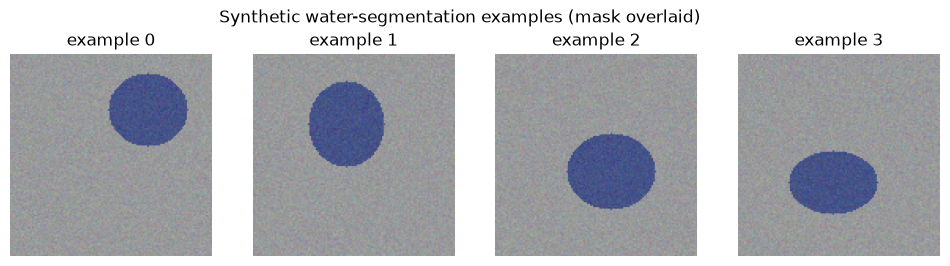

In [3]:
fig, axes = plt.subplots(1, 4, figsize=(12, 3))
for i, ax in enumerate(axes):
    ax.imshow(x_train[i])
    ax.imshow(y_train[i, ..., 1], alpha=0.35, cmap="Blues")
    ax.set_title(f"example {i}")
    ax.axis("off")
plt.suptitle("Synthetic water-segmentation examples (mask overlaid)")
plt.show()

## Model: RepViT-M0.9 backbone + PP-LiteSeg decoder

RepViT (§2.4) is one of the 4 backbone families added in this plan; it only
exposes a 4-tap feature pyramid (a patchify stem, not a single-stride-2-conv
one), so PP-LiteSeg's `feature_levels` needs the `(2, 3, 4)` override
instead of the 5-tap default `(3, 4, 5)` — the same override
`deeplab_v3_plus`/`lr_aspp` need for this backbone family, documented in
`plan.md` §2.4/§3.2.

The backbone loads real ImageNet-pretrained weights (ported from `timm`,
`plan.md` §12.2 — pass the `.weights.h5` path produced by
`scripts/port_repvit_weights.py` as `weights=`) and stays frozen throughout
training (`freeze_backbone=True`): only the PP-LiteSeg decoder's own
weights are updated. This is transfer learning, not training from scratch —
if you need the backbone itself to adapt too, pass `freeze_backbone=False`
(and expect to need more data than this notebook's synthetic set to avoid
overfitting the now much larger set of trainable parameters).

**Important**: like every decoder in this library (`deeplab_v3_plus`,
`lr_aspp`, `pp_liteseg`, `ddrnet`), `pp_liteseg`'s output is **raw logits**,
not softmax-activated probabilities — there is no final activation layer.
The new losses added in this plan (`tversky`, `lovasz_softmax`, and a
weighted-BCE written by hand below) all assume their `y_pred` argument is
already a valid probability distribution in `[0, 1]`, matching this
library's existing `dice`/`tversky` convention. Feeding raw, unbounded
logits into them directly is a real mistake this notebook's own first draft
made: `1 - y_pred` becomes deeply negative once a logit exceeds `1.0`
(routine for a confidently-trained classifier), which silently pushes
`tversky_coef` above `1.0` and the `tversky` loss well *below* `0` — the
model still trains "successfully" by gradient descent's own logic, but the
reported loss curve is nonsensical. An explicit `softmax` on the decoder's
output — done once, below — fixes this.

In [ ]:
inp = tf.keras.Input((IMG_SIZE, IMG_SIZE, 3))
logits_model = pp_liteseg(
    inp,
    n_labels=N_LABELS,
    backbone="RepViT-M0.9",
    weights="/home/matteo/Documents/work/SAK/swiss-army-keras/pretrained_weights/repvit/RepViT_M0_9.weights.h5",
    freeze_backbone=True,  # keep the pretrained backbone locked; only the decoder trains
    feature_levels=(2, 3, 4),
)

# Wrap the raw-logit decoder output in an explicit softmax - see the note
# above. `model.preprocessing` (the backbone's expected input
# normalization) is carried over by hand since building a new `Model`
# doesn't copy that custom attribute automatically.
probs = tf.keras.layers.Activation("softmax")(logits_model.output)
model = tf.keras.Model(logits_model.input, probs)
model.preprocessing = logits_model.preprocessing

model.summary()

## Loss recipe and optimizer

Following `use_case_recipes.md` §1.1's "outdoor flooding / water" row:
`0.5*Tversky(alpha=0.6) + 0.3*Lovász-Softmax + 0.2*weighted-BCE`. The
weighted-BCE term uses a mild positive-class upweighting (0.7/0.3) — outdoor
flood/water regions can be a large fraction of the frame, so this recipe
deliberately doesn't lean on Tversky's `alpha` as hard as the "indoor" rows
in the same table do.

Optimizer: **Lion** (§4.2) — note its effective learning rate is roughly an
order of magnitude smaller than Adam-family optimizers for a comparable
update size (its update is a sign, not a magnitude-scaled step).

In [5]:
def recipe_loss(y_true, y_pred):
    y_pred_clipped = tf.clip_by_value(y_pred, 1e-7, 1 - 1e-7)
    weighted_bce = -tf.reduce_mean(
        0.7 * y_true * tf.math.log(y_pred_clipped)
        + 0.3 * (1 - y_true) * tf.math.log(1 - y_pred_clipped)
    )
    return (
        0.5 * tversky(y_true, y_pred, alpha=0.6)
        + 0.3 * lovasz_softmax(y_true, y_pred)
        + 0.2 * weighted_bce
    )


model.compile(optimizer=Lion(learning_rate=1e-4), loss=recipe_loss)

In [6]:
history = model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=15,
    batch_size=32,
    verbose=2,
)

Epoch 1/15


I0000 00:00:1789117570.103904  411973 cuda_dnn.cc:461] Loaded cuDNN version 92600


I0000 00:00:1789117574.529393  411965 service.cc:153] XLA service 0x74ca8cd00460 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1789117574.529422  411965 service.cc:161]   StreamExecutor [0]: NVIDIA RTX PRO 1000 Blackwell Generation Laptop GPU, Compute Capability 12.0a (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.26.0)
I0000 00:00:1789117574.532956  411965 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1789117574.567111  411965 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


63/63 - 47s - loss: 0.3491 - val_loss: 0.3671 - 47s/epoch - 738ms/step


Epoch 2/15


63/63 - 5s - loss: 0.1178 - val_loss: 0.3083 - 5s/epoch - 86ms/step


... (22 outputs left out)

Epoch 14/15


63/63 - 5s - loss: 0.0140 - val_loss: 0.0214 - 5s/epoch - 87ms/step


Epoch 15/15


63/63 - 5s - loss: 0.0125 - val_loss: 0.0152 - 5s/epoch - 86ms/step


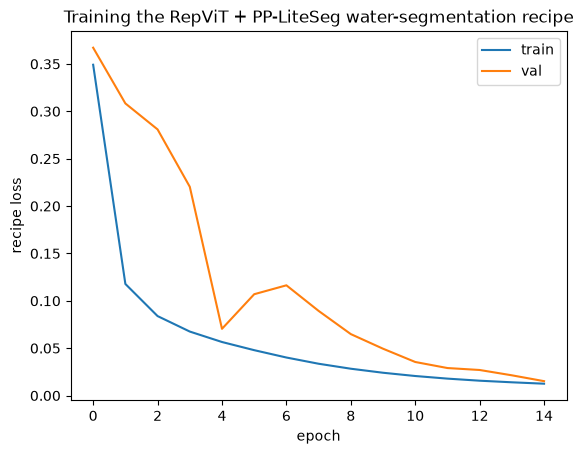

In [7]:
plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="val")
plt.xlabel("epoch")
plt.ylabel("recipe loss")
plt.legend()
plt.title("Training the RepViT + PP-LiteSeg water-segmentation recipe")
plt.show()

## Predictions on held-out synthetic examples

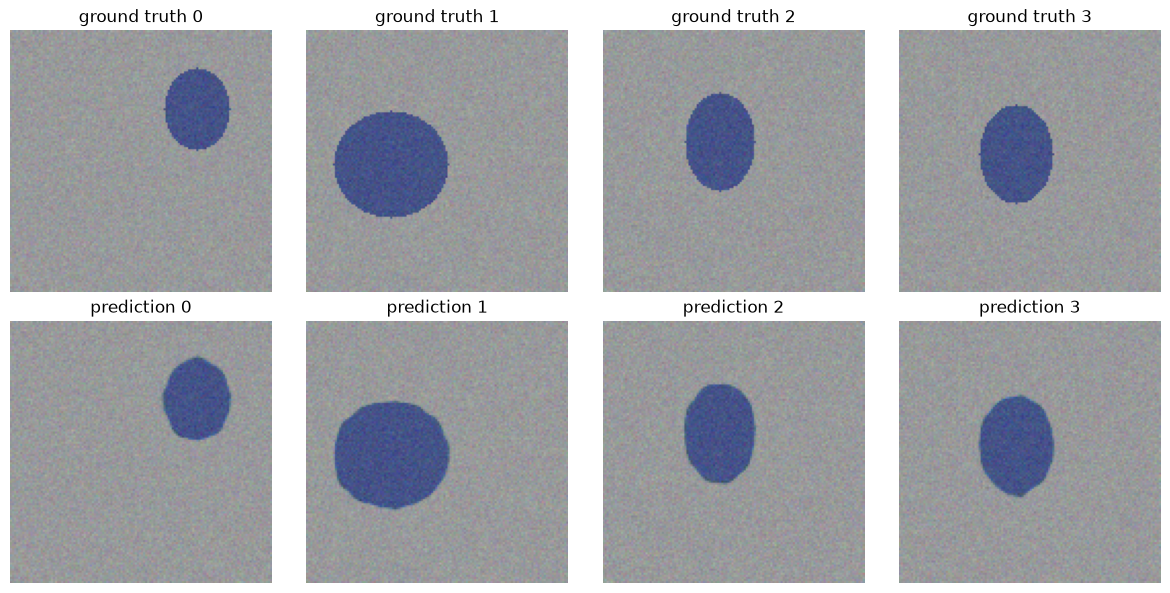

In [8]:
preds = model.predict(x_val, verbose=0)

n_show = 4
fig, axes = plt.subplots(2, n_show, figsize=(3 * n_show, 6))
for i in range(n_show):
    axes[0, i].imshow(x_val[i])
    axes[0, i].imshow(y_val[i, ..., 1], alpha=0.35, cmap="Blues")
    axes[0, i].set_title(f"ground truth {i}")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_val[i])
    axes[1, i].imshow(preds[i, ..., 1], alpha=0.35, cmap="Blues")
    axes[1, i].set_title(f"prediction {i}")
    axes[1, i].axis("off")

plt.tight_layout()
plt.show()


## Next steps

- Swap the synthetic data generator for a real water/flood-segmentation
  dataset to validate this recipe for real (`plan.md` §13 Phase 8).
- Try the other 3 backbone families (MobileOne, MobileNetV4, FastViT) or
  the other 2 new decoders (LR-ASPP, DDRNet) with the same loss recipe —
  swapping `backbone=`/the decoder function is the only change needed
  (remember the raw-logits-need-softmax note above applies to all of them).
- See `use_case_recipes.md` for the "indoor water", "outdoor smoke", and
  "indoor smoke" loss recipes, each tuned differently for that scenario's
  imbalance/boundary characteristics.